# IPL model comparison

This notebook compares the models we have tried so far, using the same features, validation folds and later-season holdout.

The Random Forest and XGBoost settings come from their tuning notebooks. The other models use the configurations from their existing experiments. This is a practical comparison, not an exhaustive search for every model.

In [9]:
from pathlib import Path
import gc
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

try:
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier
except ImportError as exc:
    raise ImportError(
        "This notebook needs xgboost and lightgbm. Install them in this environment with: "
        "python -m pip install xgboost lightgbm"
    ) from exc

## 1. Load the data

We use seasons through 2024 to fit and compare models. Seasons 2025 onward are held back for a time-based check. `match_id` is only used for splitting; it is not a feature.

In [10]:
# Find the project folder whether VS Code opened the notebook from the root or src/.
SEARCH_ROOTS = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
DATA_RELATIVE = Path("data/processed/reduced/Final_data.csv")
DATA_PATH = next((p / DATA_RELATIVE for p in SEARCH_ROOTS if (p / DATA_RELATIVE).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Can't find data/processed/reduced/Final_data.csv. Open this notebook inside the project folder."
    )

PROJECT_ROOT = next((p for p in SEARCH_ROOTS if (p / ".git").exists()), DATA_PATH.resolve().parents[3])
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ["target_runs", "runs_left", "CRR", "balls_left", "RRR", "wickets_left"]
TARGET = "won"
GROUP = "match_id"

df = pd.read_csv(DATA_PATH)

In [11]:
required = FEATURES + [TARGET, GROUP, "season_id"]
assert df[required].notna().all().all(), "One or more required columns contain missing values."
assert set(df[TARGET].unique()).issubset({0, 1}), "The target should contain 0/1 labels."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has inconsistent target labels."

dev = df.loc[df["season_id"] <= 2024].reset_index(drop=True)
test = df.loc[df["season_id"] >= 2025].reset_index(drop=True)
assert not dev.empty and not test.empty, "Need both development seasons and a 2025+ holdout."
assert set(dev[GROUP]).isdisjoint(set(test[GROUP])), "A match appears in both data splits."

X_dev, y_dev, groups_dev = dev[FEATURES], dev[TARGET].astype(int), dev[GROUP]
X_test, y_test = test[FEATURES], test[TARGET].astype(int)

print(f"Loaded {len(df):,} rows across {df[GROUP].nunique():,} matches")
print(f"Development: {len(dev):,} rows across {groups_dev.nunique():,} matches (through 2024)")
print(f"Holdout: {len(test):,} rows across {test[GROUP].nunique():,} matches (2025 onward)")
print(f"Latest holdout date: {test['match_date'].max() if 'match_date' in test.columns else 'not available'}")

Loaded 117,558 rows across 1,063 matches
Development: 105,663 rows across 953 matches (through 2024)
Holdout: 11,895 rows across 110 matches (2025 onward)
Latest holdout date: 2026-05-01


## 2. Load the tuned settings

The tuning notebooks save their selected settings as JSON files in `reports/`. This cell loads those files. If one is missing, it uses the best settings from the completed tuning runs shared so far and prints a warning.

In [12]:
RF_FALLBACK = {
    "n_estimators": 120,
    "min_samples_leaf": 150,
    "max_features": "sqrt",
    "max_depth": 12,
}

XGB_FALLBACK = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "n_estimators": 350,
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_child_weight": 10,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}

def load_best_params(filename, fallback):
    path = REPORT_DIR / filename
    params = fallback.copy()
    if path.exists():
        with path.open("r", encoding="utf-8") as f:
            params.update(json.load(f))
        print(f"Loaded selected settings from {path.name}")
    else:
        print(f"Warning: {path.name} not found; using the settings from the latest tuning run.")
    return params

RF_PARAMS = load_best_params("random_forest_best_params.json", RF_FALLBACK)
XGB_PARAMS = load_best_params("xgboost_best_params.json", XGB_FALLBACK)

print("Random Forest settings:", RF_PARAMS)
print("XGBoost settings:", XGB_PARAMS)

Loaded selected settings from random_forest_best_params.json
Loaded selected settings from xgboost_best_params.json
Random Forest settings: {'n_estimators': 120, 'min_samples_leaf': 150, 'max_features': 'sqrt', 'max_depth': 12}
XGBoost settings: {'objective': 'binary:logistic', 'eval_metric': 'logloss', 'n_estimators': 350, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5, 'tree_method': 'hist', 'n_jobs': -1, 'random_state': 42, 'verbosity': 0}


## 3. Set up the models

We keep this list to the models already tested. The RBF SVM is trained on a reproducible sample of up to 8,000 rows because it is much slower than the linear version. The SVM probability calibration uses grouped splits too.

In [13]:
MODEL_NAMES = [
    "Logistic Regression",
    "Linear SVM (calibrated)",
    "RBF SVM (8k sample, calibrated)",
    "Random Forest",
    "Extra Trees",
    "Hist Gradient Boosting",
    "XGBoost",
    "LightGBM",
]
RBF_SAMPLE_SIZE = 8_000

MODEL_COLUMNS = {
    "Logistic Regression": "p_logistic_regression",
    "Linear SVM (calibrated)": "p_linear_svm",
    "RBF SVM (8k sample, calibrated)": "p_rbf_svm_sampled",
    "Random Forest": "p_random_forest",
    "Extra Trees": "p_extra_trees",
    "Hist Gradient Boosting": "p_hist_gradient_boosting",
    "XGBoost": "p_xgboost",
    "LightGBM": "p_lightgbm",
}

def build_model(name, X_fit, y_fit, groups_fit, seed=42):
    if name == "Logistic Regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000)),
        ])

    if name == "Linear SVM (calibrated)":
        inner_cv = list(GroupKFold(n_splits=3).split(X_fit, y_fit, groups_fit))
        return CalibratedClassifierCV(
            estimator=Pipeline([
                ("scale", StandardScaler()),
                ("svm", LinearSVC(C=1.0, max_iter=5000, random_state=seed)),
            ]),
            method="sigmoid",
            cv=inner_cv,
            ensemble=False,
        )

    if name == "RBF SVM (8k sample, calibrated)":
        inner_cv = list(GroupKFold(n_splits=3).split(X_fit, y_fit, groups_fit))
        return CalibratedClassifierCV(
            estimator=Pipeline([
                ("scale", StandardScaler()),
                ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=500)),
            ]),
            method="sigmoid",
            cv=inner_cv,
            ensemble=False,
        )

    if name == "Random Forest":
        return RandomForestClassifier(n_jobs=-1, random_state=seed, **RF_PARAMS)

    if name == "Extra Trees":
        return ExtraTreesClassifier(
            n_estimators=80, min_samples_leaf=100, max_features="sqrt",
            n_jobs=-1, random_state=seed,
        )

    if name == "Hist Gradient Boosting":
        return HistGradientBoostingClassifier(
            max_iter=100, learning_rate=0.08, max_leaf_nodes=15,
            min_samples_leaf=50, l2_regularization=5.0,
            early_stopping=False, random_state=seed,
        )

    if name == "XGBoost":
        params = XGB_PARAMS.copy()
        params["random_state"] = seed
        params["n_jobs"] = -1
        return XGBClassifier(**params)

    if name == "LightGBM":
        return LGBMClassifier(
            objective="binary", n_estimators=300, learning_rate=0.05,
            num_leaves=15, max_depth=5, min_child_samples=100,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            reg_lambda=5, importance_type="gain", n_jobs=-1,
            random_state=seed, verbosity=-1,
        )

    raise ValueError(f"Unknown model: {name}")


def fit_candidate(name, X_fit, y_fit, groups_fit, seed=42):
    # RBF SVM is the only model that uses a smaller training sample.
    if name == "RBF SVM (8k sample, calibrated)" and len(X_fit) > RBF_SAMPLE_SIZE:
        sample_idx = np.random.RandomState(seed).choice(
            len(X_fit), size=RBF_SAMPLE_SIZE, replace=False
        )
        X_fit = X_fit.iloc[sample_idx].reset_index(drop=True)
        y_fit = y_fit.iloc[sample_idx].reset_index(drop=True)
        groups_fit = groups_fit.iloc[sample_idx].reset_index(drop=True)

    model = build_model(name, X_fit, y_fit, groups_fit, seed=seed)
    model.fit(X_fit, y_fit)
    return model, len(X_fit)


def score_probabilities(y_true, probabilities):
    probabilities = np.clip(np.asarray(probabilities), 1e-6, 1 - 1e-6)
    return {
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "brier": brier_score_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, probabilities >= 0.5),
    }

## 4. Compare models on the same five folds

Every model gets the same five match-grouped train/validation splits. Rows from one match stay together, so the same match cannot appear in both sides of a fold.

This reuses the RF and XGBoost settings selected in the earlier tuning notebooks. Because their settings were selected using the development data, their five-fold scores here are a useful standardized comparison but not a fully independent estimate of the tuning process.

In [14]:
outer_cv = GroupKFold(n_splits=5)
outer_splits = list(outer_cv.split(X_dev, y_dev, groups_dev))
cv_rows = []
oof_predictions = pd.DataFrame({
    GROUP: groups_dev,
    "season_id": dev["season_id"],
    "y_true": y_dev,
    "fold": np.zeros(len(dev), dtype=int),
})
for col in MODEL_COLUMNS.values():
    oof_predictions[col] = np.nan

for fold, (train_idx, val_idx) in enumerate(outer_splits, start=1):
    X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
    groups_train, groups_val = groups_dev.iloc[train_idx], groups_dev.iloc[val_idx]

    assert set(groups_train).isdisjoint(set(groups_val)), "A match leaked across folds."
    oof_predictions.loc[val_idx, "fold"] = fold

    for name in MODEL_NAMES:
        start = time.perf_counter()
        model, rows_used = fit_candidate(
            name, X_train, y_train, groups_train, seed=42 + fold
        )
        p_val = model.predict_proba(X_val)[:, 1]
        scores = score_probabilities(y_val, p_val)
        cv_rows.append({
            "model": name,
            "fold": fold,
            **scores,
            "train_rows_used": rows_used,
            "fit_and_score_seconds": time.perf_counter() - start,
        })
        oof_predictions.loc[val_idx, MODEL_COLUMNS[name]] = p_val
        print(f"Fold {fold}/5 | {name}: log loss = {scores['log_loss']:.4f}")
        del model
        gc.collect()

cv_results = pd.DataFrame(cv_rows)
assert not oof_predictions[list(MODEL_COLUMNS.values())].isna().any().any()
assert (oof_predictions["fold"] > 0).all()

cv_summary = (
    cv_results.groupby("model")
    .agg(
        log_loss_mean=("log_loss", "mean"),
        log_loss_std=("log_loss", "std"),
        brier_mean=("brier", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
        total_fit_seconds=("fit_and_score_seconds", "sum"),
    )
    .sort_values("log_loss_mean")
)
display(cv_summary.round(4))

Fold 1/5 | Logistic Regression: log loss = 0.4273
Fold 1/5 | Linear SVM (calibrated): log loss = 0.4272
Fold 1/5 | RBF SVM (8k sample, calibrated): log loss = 0.4522
Fold 1/5 | Random Forest: log loss = 0.4481
Fold 1/5 | Extra Trees: log loss = 0.4693
Fold 1/5 | Hist Gradient Boosting: log loss = 0.4640
Fold 1/5 | XGBoost: log loss = 0.4431
Fold 1/5 | LightGBM: log loss = 0.4768
Fold 2/5 | Logistic Regression: log loss = 0.4609
Fold 2/5 | Linear SVM (calibrated): log loss = 0.4608
Fold 2/5 | RBF SVM (8k sample, calibrated): log loss = 0.4671
Fold 2/5 | Random Forest: log loss = 0.4903
Fold 2/5 | Extra Trees: log loss = 0.4974
Fold 2/5 | Hist Gradient Boosting: log loss = 0.4862
Fold 2/5 | XGBoost: log loss = 0.4772
Fold 2/5 | LightGBM: log loss = 0.4958
Fold 3/5 | Logistic Regression: log loss = 0.4736
Fold 3/5 | Linear SVM (calibrated): log loss = 0.4726
Fold 3/5 | RBF SVM (8k sample, calibrated): log loss = 0.5013
Fold 3/5 | Random Forest: log loss = 0.4903
Fold 3/5 | Extra Trees: lo

,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean,total_fit_seconds
model,,,,,,
Logistic Regression,0.4405,0.0250,0.1454,0.8744,0.7839,0.5063
Linear SVM (calibrated),0.4406,0.0243,0.1453,0.8744,0.7839,1.7853
XGBoost,0.4515,0.0372,0.1473,0.8703,0.7789,2.7187
Random Forest,0.4576,0.0309,0.1500,0.8658,0.7746,6.7676
"RBF SVM (8k sample, calibrated)",0.4630,0.0229,0.1506,0.8672,0.7815,34.6150
Hist Gradient Boosting,0.4731,0.0407,0.1540,0.8590,0.7696,1.5189
Extra Trees,0.4838,0.0135,0.1566,0.8677,0.7792,2.4111
LightGBM,0.4860,0.0349,0.1579,0.8543,0.7626,1.8417


## 5. Pooled out-of-fold scores

The table above averages each fold's scores. This next table puts all out-of-fold predictions together and scores them as one set. Each development row gets a prediction from a model that did not train on that row's match.

In [15]:
oof_rows = []
for name, column in MODEL_COLUMNS.items():
    oof_rows.append({"model": name, **score_probabilities(oof_predictions["y_true"], oof_predictions[column])})
oof_summary = pd.DataFrame(oof_rows).set_index("model").sort_values("log_loss")
display(oof_summary.round(4))

,log_loss,brier,roc_auc,accuracy
model,,,,
Logistic Regression,0.4405,0.1454,0.8730,0.7839
Linear SVM (calibrated),0.4406,0.1453,0.8731,0.7839
XGBoost,0.4515,0.1473,0.8687,0.7789
Random Forest,0.4576,0.1500,0.8642,0.7746
"RBF SVM (8k sample, calibrated)",0.4630,0.1506,0.8645,0.7815
Hist Gradient Boosting,0.4731,0.1540,0.8575,0.7696
Extra Trees,0.4838,0.1567,0.8662,0.7792
LightGBM,0.4861,0.1579,0.8532,0.7626


## 6. Check the later seasons

Now we fit each model on all seasons through 2024 and score the same matches from 2025 onward. We've already looked at these later-season results in the individual experiments, so treat this as a time-based validation comparison rather than a completely untouched final test.

In [16]:
holdout_rows = []
temporal_predictions = pd.DataFrame({
    GROUP: test[GROUP],
    "season_id": test["season_id"],
    "y_true": y_test,
})

for name in MODEL_NAMES:
    start = time.perf_counter()
    model, rows_used = fit_candidate(name, X_dev, y_dev, groups_dev, seed=2026)
    p_test = model.predict_proba(X_test)[:, 1]
    scores = score_probabilities(y_test, p_test)
    holdout_rows.append({
        "model": name,
        **scores,
        "train_rows_used": rows_used,
        "fit_and_score_seconds": time.perf_counter() - start,
    })
    temporal_predictions[MODEL_COLUMNS[name]] = p_test
    print(f"{name}: holdout log loss = {scores['log_loss']:.4f}")
    del model
    gc.collect()

holdout_results = (
    pd.DataFrame(holdout_rows)
    .set_index("model")
    .sort_values("log_loss")
)
display(holdout_results.round(4))

Logistic Regression: holdout log loss = 0.4244
Linear SVM (calibrated): holdout log loss = 0.4273
RBF SVM (8k sample, calibrated): holdout log loss = 0.4607
Random Forest: holdout log loss = 0.4479
Extra Trees: holdout log loss = 0.4773
Hist Gradient Boosting: holdout log loss = 0.5993
XGBoost: holdout log loss = 0.4883
LightGBM: holdout log loss = 0.6498


,log_loss,brier,roc_auc,accuracy,train_rows_used,fit_and_score_seconds
model,,,,,,
Logistic Regression,0.4244,0.1391,0.9001,0.7935,105663,0.1087
Linear SVM (calibrated),0.4273,0.1398,0.8994,0.7929,105663,0.3785
Random Forest,0.4479,0.1471,0.8918,0.7908,105663,1.7916
"RBF SVM (8k sample, calibrated)",0.4607,0.1495,0.8914,0.7844,8000,5.0287
Extra Trees,0.4773,0.1547,0.9025,0.7804,105663,0.5553
XGBoost,0.4883,0.1607,0.8750,0.7637,105663,0.6357
Hist Gradient Boosting,0.5993,0.1844,0.8492,0.7575,105663,0.2949
LightGBM,0.6498,0.1939,0.8405,0.7466,105663,0.3752


## 7. Compare log loss and calibration

Lower log loss is better. The calibration plot checks whether predictions of (say) 70% win probability actually win around 70% of the time.

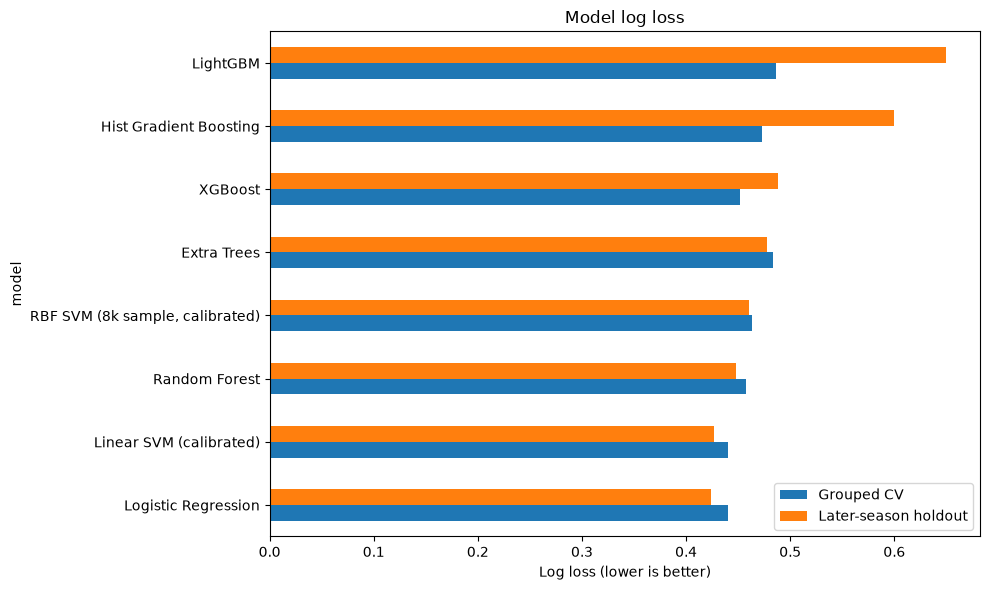

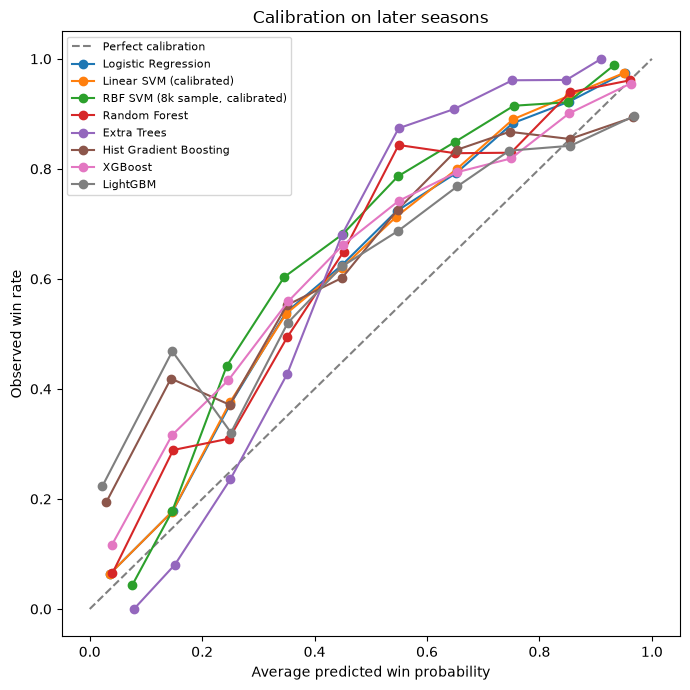

In [17]:
plot_data = cv_summary[["log_loss_mean"]].rename(columns={"log_loss_mean": "Grouped CV"}).join(
    holdout_results[["log_loss"]].rename(columns={"log_loss": "Later-season holdout"}), how="outer"
).sort_values("Later-season holdout")
plot_data.plot(kind="barh", figsize=(10, 6), xlabel="Log loss (lower is better)", title="Model log loss")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
for name, column in MODEL_COLUMNS.items():
    observed, predicted = calibration_curve(
        y_test, temporal_predictions[column], n_bins=10, strategy="uniform"
    )
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlabel="Average predicted win probability", ylabel="Observed win rate", title="Calibration on later seasons")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## 8. Save the results

The score tables go in `reports/`. The row-by-row prediction files go in `data/processed/` so we can use them for ensemble experiments later. Since those prediction files can be large, keep them local unless you specifically want to version them.

In [18]:
cv_results.to_csv(REPORT_DIR / "model_comparison_grouped_cv_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "model_comparison_grouped_cv_summary.csv")
oof_summary.to_csv(REPORT_DIR / "model_comparison_oof_summary.csv")
holdout_results.to_csv(REPORT_DIR / "model_comparison_temporal_holdout.csv")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
oof_predictions.to_csv(PROCESSED_DIR / "model_comparison_oof_predictions.csv", index=False)
temporal_predictions.to_csv(PROCESSED_DIR / "model_comparison_temporal_predictions.csv", index=False)

print(f"Score reports saved to: {REPORT_DIR}")
print(f"Prediction files saved to: {PROCESSED_DIR}")

Score reports saved to: C:\Users\Lenovo\Documents\IPL ML\reports
Prediction files saved to: C:\Users\Lenovo\Documents\IPL ML\data\processed
